# NB06 — Perfect-foresight optimisation across tariffs (2023)

**SOLA4237 Assignment 2 — single-site battery optimisation, Toowoomba (QLD)**

**Purpose.** Run the chosen battery (13.5 kWh / 5 kW, notebook) over **2023** under the three tariffs and compare four scenarios:

| Scenario | What it is |
|---|---|
| S0 | No PV, no battery (all load imported) — from notebook 2 |
| S1 | PV only |
| S2 | PV + battery, **self-consumption** (default mode in the brief; benchmark) |
| S3 | PV + battery, **cost-optimised with perfect foresight** (run R1: actual PV and actual prices known 48 h ahead) |

S3 is the **upper bound** on what any forecast-based strategy can achieve; notebook 7 measures how much of it survives with forecasts.
Operation: a new 48 h hourly plan every hour, 5-min execution with the actual SoC, settlement at actual 5-min prices.

**Inputs:** `outputs/nb01_clean_2022_2023.csv`, `outputs/nb02_bills_S0_S1.csv`, `bess_functions.py`.
**Outputs:** `outputs/nb06_results_2023.csv`, `outputs/nb06_monthly_2023.csv`, `outputs/nb06_dispatch_<tariff>_<scenario>.csv.gz`
(5-min results reused by NB07–NB08), figures fig09a–fig09c. **Run order:** after NB01, NB02, NB05.

## Cell 0 — Settings

In [1]:
# Cell 0 - Settings: runs in Google Colab and in local Jupyter
import sys, os
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE_DIR = '/content/drive/MyDrive/SOLA4237-A2'
else:
    BASE_DIR = os.getcwd()                    # local: the data folder or its 'Notebook' subfolder
    if not os.path.exists(os.path.join(BASE_DIR, 'QLD_spot_price_2023')):
        BASE_DIR = os.path.dirname(BASE_DIR)
sys.path.append(BASE_DIR)
OUT_DIR = os.path.join(BASE_DIR, 'outputs')
FIG_DIR = os.path.join(OUT_DIR, 'figures')
os.makedirs(FIG_DIR, exist_ok=True)
assert os.path.exists(os.path.join(BASE_DIR, 'bess_functions.py')), 'Upload bess_functions.py to ' + BASE_DIR
print('BASE_DIR:', BASE_DIR)

Mounted at /content/drive
BASE_DIR: /content/drive/MyDrive/SOLA4237-A2


## Cell 1 — Imports and 2023 data
The 2023 year runs from label 2023-01-01 00:05 to 2023-12-31 23:55 (105,119 intervals; the 00:00 label of 1 Jan 2024 is not in the dataset).
The $300/yr VPP fee applies only where the battery trades with the wholesale market, i.e. **S3 under the wholesale tariff**.

In [2]:
# Cell 1 - imports and data
import time, importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import bess_functions as bf
importlib.reload(bf)

DT_H = 5 / 60
VPP_FEE_AUD = 300.0
TARIFFS = {'flat': ('import_flat_aud_kwh', 'export_flat_aud_kwh'),
           'tou': ('import_tou_aud_kwh', 'export_tou_aud_kwh'),
           'wholesale': ('import_wholesale_aud_kwh', 'export_wholesale_aud_kwh')}
COL = {'flat': '#4c72b0', 'tou': '#55a868', 'wholesale': '#c44e52', 'load': '#1f4e79', 'pv': '#f2a900', 'bat': '#55a868', 'soc': '#7f7f7f'}
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 20)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3, 'axes.spines.top': False, 'axes.spines.right': False})

df = pd.read_csv(os.path.join(OUT_DIR, 'nb01_clean_2022_2023.csv'), parse_dates=['datetime']).set_index('datetime')
y23 = df.loc['2023-01-01 00:05':'2023-12-31 23:55']
s0 = pd.read_csv(os.path.join(OUT_DIR, 'nb02_bills_S0_S1.csv')).set_index('tariff')
print('2023 intervals:', len(y23), '| load %.0f kWh | PV %.0f kWh' % (y23.load_kw.sum() * DT_H, y23.pv_actual_kw.sum() * DT_H))

2023 intervals: 105119 | load 11217 kWh | PV 21248 kWh


## Cell 2 — Run S1, S2 and S3 for each tariff
S3 re-plans every hour (8,760 LPs per tariff). Curtailment is allowed only under the wholesale tariff (only there can the export price be
negative). Each run is timed so the runtime can be reported.

In [3]:
# Cell 2 - run the scenarios
runs = {}
for tname, (ic, ec) in TARIFFS.items():
    runs[(tname, 'S1')] = bf.no_battery(y23, ic, ec)
    runs[(tname, 'S2')] = bf.run_operation(y23, ic, ec, mode='selfcons')
    t0 = time.time()
    runs[(tname, 'S3')] = bf.run_operation(y23, ic, ec, mode='cost', allow_curtail=(tname == 'wholesale'), replan_h=1)
    print(f'{tname:9s} S3 done in {time.time() - t0:.0f} s')

flat      S3 done in 90 s
tou       S3 done in 87 s
wholesale S3 done in 84 s


## Cell 3 — Results table (bills and key performance indicators)
**Bill** = energy cost for 2023 (import cost − export revenue), excluding the daily supply charge (same for all scenarios) and
including the VPP fee for wholesale S3. **Self-consumption** = share of PV used on site (directly or via the battery);
**self-sufficiency** = share of load not imported; **cycles** = discharged energy ÷ 13.5 kWh.

In [4]:
# Cell 3 - results table
rows = []
for tname in TARIFFS:
    rows.append({'tariff': tname, 'scenario': 'S0', 'bill_aud': s0.loc[tname, 'S0_no_pv_aud']})
    for sc in ['S1', 'S2', 'S3']:
        fee = VPP_FEE_AUD if (tname == 'wholesale' and sc == 'S3') else 0.0
        st = bf.settle(runs[(tname, sc)], fee_aud=fee)
        st.update({'tariff': tname, 'scenario': sc, 'vpp_fee_aud': fee})
        rows.append(st)
res = pd.DataFrame(rows)
bills = res.pivot(index='scenario', columns='tariff', values='bill_aud')
print('Annual bill 2023 ($):'); print(bills.round(0))
print('\nSaving of the battery vs PV only (S1) and S3 vs the self-consumption benchmark (S2) ($/yr):')
sav = pd.DataFrame({'S2 vs S1': bills.loc['S1'] - bills.loc['S2'], 'S3 vs S1': bills.loc['S1'] - bills.loc['S3'],
                    'S3 vs S2': bills.loc['S2'] - bills.loc['S3']})
print(sav.round(0))
kpi_cols = ['import_kwh', 'export_kwh', 'battery_export_kwh', 'curtailed_kwh', 'self_consumption', 'self_sufficiency',
            'equivalent_full_cycles', 'max_balance_error_kw']
kpi = res[res.scenario != 'S0'].set_index(['tariff', 'scenario'])[kpi_cols]
kpi.round(3)

Annual bill 2023 ($):
tariff      flat     tou  wholesale
scenario                           
S0        3365.0  2876.0     2142.0
S1         795.0   618.0     1023.0
S2          87.0   -33.0      199.0
S3         107.0   -70.0     -159.0

Saving of the battery vs PV only (S1) and S3 vs the self-consumption benchmark (S2) ($/yr):
           S2 vs S1  S3 vs S1  S3 vs S2
tariff                                 
flat          707.0     688.0     -19.0
tou           652.0     689.0      37.0
wholesale     824.0    1182.0     357.0


import_kwh  export_kwh  battery_export_kwh  curtailed_kwh  self_consumption  self_sufficiency  equivalent_full_cycles  max_balance_error_kw
tariff    scenario                                                                                                                                             
flat      S1          5184.810   15215.315               0.000          0.000             0.284             0.538                   0.000                   0.0
          S2          2291.765   12002.923               0.000          0.000             0.435             0.796                 214.300                   0.0
          S3          2371.785   12094.196               0.000          0.000             0.431             0.789                 208.372                   0.0
tou       S1          5184.810   15215.315               0.000          0.000             0.284             0.538                   0.000                   0.0
          S2          2291.765   12002.923               0.000          0.000             0.435             0.796                 214.300                   0.0
          S3          2438.534   12163.915               0.000          0.000             0.428             0.783                 206.379                   0.0
wholesale S1          5184.810   15215.315               0.000          0.000             0.284             0.538                   0.000                   0.0
          S2          2291.765   12002.923               0.000          0.000             0.435             0.796                 214.300                   0.0
          S3          3339.265    9015.638            1292.913       3982.064             0.449             0.702                 251.251                   0.0

## Cell 4 — Checks on the S3 runs
1. energy balance closes at every interval; 2. SoC stays within 10–95 %; 3. the battery never charges and discharges at the same time
(a single signed power per interval, so this holds by construction); 4. **warranty throughput** — the plan limits discharge to
10.4 kWh/day, but 5-min execution follows the plan's grid target, so on some days actual discharge can differ from the plan. We report how often
the cap is exceeded and by how much. The warranty itself is **cumulative** (37.8 MWh over 10 years ≈ 3,796 kWh/yr), so the
binding test is the **annual** discharge; the daily cap is only the planning proxy. 5. **Curtailment** should happen almost only when the
5-min export price is negative (the decision uses the plan's hourly price, so a little can fall in positive 5-min intervals).

In [5]:
# Cell 4 - checks
cap = bf.BATTERY['max_dis_kwh_day']
chk = []
for tname in TARIFFS:
    r = runs[(tname, 'S3')]
    daily_dis = r.p_bat_kw.clip(lower=0).resample('D').sum() * DT_H
    chk.append({'tariff': tname,
                'max_balance_error_kw': bf.settle(r)['max_balance_error_kw'],
                'soc_min_kwh': r.soc_kwh.min(), 'soc_max_kwh': r.soc_kwh.max(),
                'days_over_cap': int((daily_dis > cap + 0.01).sum()),
                'max_daily_discharge_kwh': daily_dis.max(),
                'mean_daily_discharge_kwh': daily_dis.mean(),
                'annual_discharge_kwh': daily_dis.sum(), 'annual_warranty_kwh': cap * 365,
                'curtailed_kwh': r.curt_kw.sum() * DT_H,
                'curtailed_at_negative_price_kwh': r.curt_kw[r.export_price < 0].sum() * DT_H})
chk = pd.DataFrame(chk).set_index('tariff')
neg = y23.spot_aud_kwh < 0
day = (y23.index.hour >= 8) & (y23.index.hour < 16)
s1w = runs[('wholesale', 'S1')]
print('Spot price negative in %.1f %% of all and %.1f %% of daytime (08-16 h) intervals in 2023' % (100 * neg.mean(), 100 * neg[day].mean()))
print('PV only (S1) would export %.0f kWh at negative prices\n' % (s1w.export_kw[s1w.export_price < 0].sum() * DT_H))
print(chk.round(3))
assert (chk.max_balance_error_kw < 1e-6).all()
assert (chk.soc_min_kwh >= 0.10 * 13.5 - 1e-6).all() and (chk.soc_max_kwh <= 0.95 * 13.5 + 1e-6).all()
print('annual discharge within the warranty throughput:', (chk.annual_discharge_kwh <= chk.annual_warranty_kwh).to_dict())

Spot price negative in 13.5 % of all and 37.4 % of daytime (08-16 h) intervals in 2023
PV only (S1) would export 6260 kWh at negative prices

           max_balance_error_kw  soc_min_kwh  soc_max_kwh  days_over_cap  max_daily_discharge_kwh  mean_daily_discharge_kwh  annual_discharge_kwh  annual_warranty_kwh  curtailed_kwh  \
tariff                                                                                                                                                                                  
flat                        0.0         1.35       12.825             93                   15.198                     7.707              2813.025               3796.0          0.000   
tou                         0.0         1.35       12.825             74                   15.195                     7.633              2786.111               3796.0          0.000   
wholesale                   0.0         1.35       12.825            156                   18.885                     

## Cell 5 — Dispatch: two summer and two winter days under each tariff (S3)
Days chosen from the price data: **8–9 Jan 2023** (lowest summer price, negative at midday → curtailment/charging opportunity) and
**12–13 Jun 2023** (highest daily mean price in winter, evening spikes). **Look for:** when the battery charges (PV or grid), when it
discharges, and whether the three tariffs lead to different behaviour.

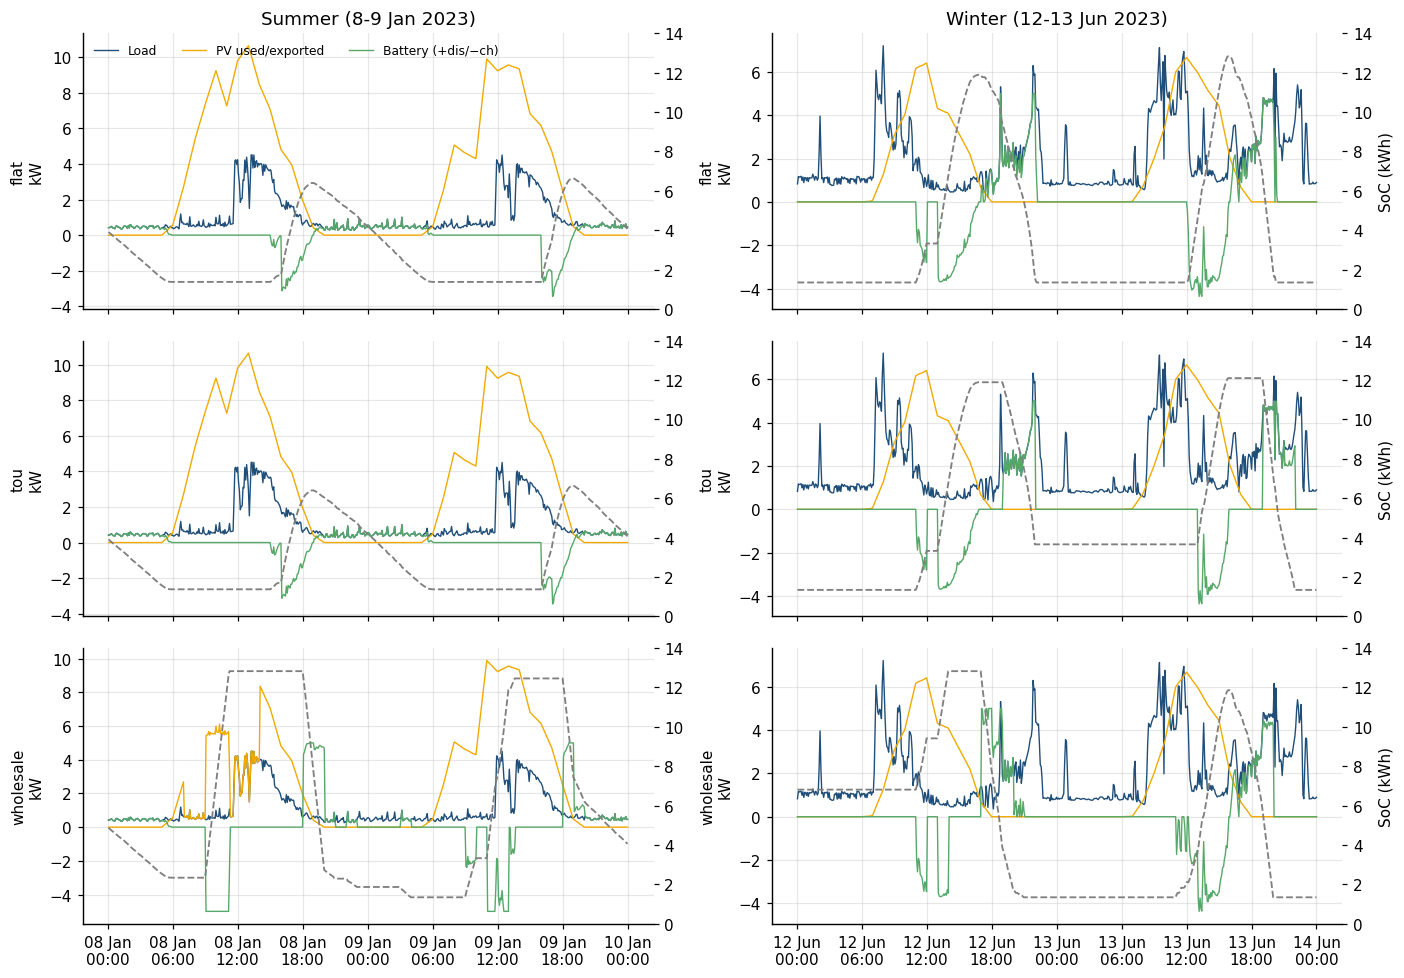

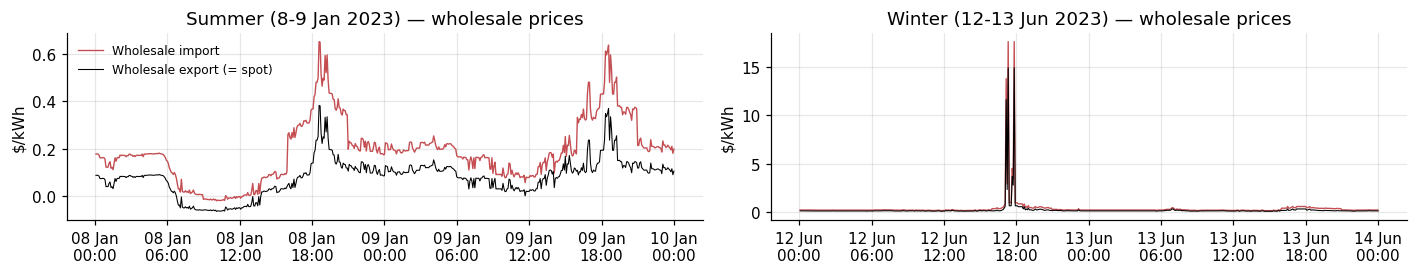

In [6]:
# Cell 5 - two-day dispatch plots
DAYS = {'Summer (8-9 Jan 2023)': ('2023-01-08 00:05', '2023-01-10 00:00'),
        'Winter (12-13 Jun 2023)': ('2023-06-12 00:05', '2023-06-14 00:00')}
fig, ax = plt.subplots(3, 2, figsize=(13, 9), sharex='col')
for j, (dname, (a, b)) in enumerate(DAYS.items()):
    for i, tname in enumerate(TARIFFS):
        r = runs[(tname, 'S3')].loc[a:b]
        axi = ax[i, j]
        axi.plot(r.index, r.load_kw, color=COL['load'], lw=0.9, label='Load')
        axi.plot(r.index, r.pv_kw - r.curt_kw, color=COL['pv'], lw=0.9, label='PV used/exported')
        axi.plot(r.index, r.p_bat_kw, color=COL['bat'], lw=0.9, label='Battery (+dis/−ch)')
        axi.set_ylabel(f'{tname}\nkW')
        a2 = axi.twinx(); a2.plot(r.index, r.soc_kwh, color=COL['soc'], lw=1.2, ls='--', label='SoC'); a2.set_ylim(0, 14); a2.grid(False)
        if j == 1: a2.set_ylabel('SoC (kWh)')
        if i == 0: axi.set_title(dname)
        axi.xaxis.set_major_locator(mdates.HourLocator(byhour=[0, 6, 12, 18]))
        axi.xaxis.set_major_formatter(mdates.DateFormatter('%d %b\n%H:%M'))
ax[0, 0].legend(ncol=3, frameon=False, fontsize=8, loc='upper left')
plt.tight_layout(); fig.savefig(os.path.join(FIG_DIR, 'fig09a_dispatch_days_S3.png'), dpi=200, bbox_inches='tight'); plt.show()

# prices on the same days (context for the wholesale panels)
fig, ax = plt.subplots(1, 2, figsize=(13, 2.6))
for j, (dname, (a, b)) in enumerate(DAYS.items()):
    p = y23.loc[a:b]
    ax[j].plot(p.index, p.import_wholesale_aud_kwh, color=COL['wholesale'], lw=0.9, label='Wholesale import')
    ax[j].plot(p.index, p.export_wholesale_aud_kwh, color='k', lw=0.7, label='Wholesale export (= spot)')
    ax[j].set_title(dname + ' — wholesale prices'); ax[j].set_ylabel('$/kWh')
    ax[j].xaxis.set_major_locator(mdates.HourLocator(byhour=[0, 6, 12, 18]))
    ax[j].xaxis.set_major_formatter(mdates.DateFormatter('%d %b\n%H:%M'))
ax[0].legend(frameon=False, fontsize=8)
plt.tight_layout(); fig.savefig(os.path.join(FIG_DIR, 'fig09b_dispatch_days_prices.png'), dpi=200, bbox_inches='tight'); plt.show()

## Cell 6 — Where the value comes from: monthly savings of S3 vs S1

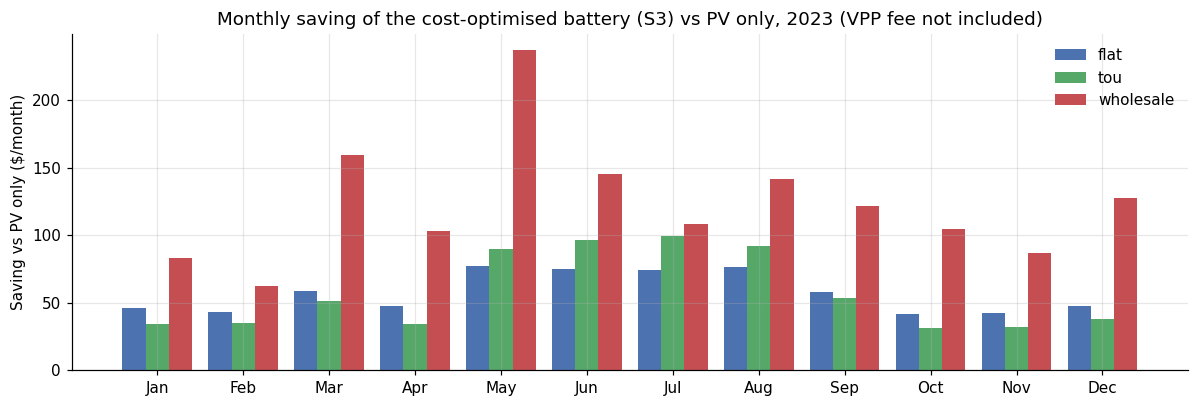

datetime    Jan   Feb    Mar    Apr    May    Jun    Jul    Aug    Sep    Oct   Nov    Dec
flat       46.0  43.0   59.0   48.0   77.0   75.0   74.0   77.0   58.0   42.0  43.0   47.0
tou        34.0  35.0   51.0   34.0   90.0   97.0  100.0   92.0   54.0   32.0  32.0   38.0
wholesale  83.0  63.0  160.0  103.0  237.0  146.0  108.0  142.0  121.0  105.0  87.0  128.0

Wholesale: top 3 months give 37 % of the annual saving


In [7]:
# Cell 6 - monthly savings
monthly = {}
for tname in TARIFFS:
    for sc in ['S1', 'S2', 'S3']:
        monthly[(tname, sc)] = runs[(tname, sc)].cost_aud.resample('MS').sum()
monthly = pd.DataFrame(monthly)
monthly.index = monthly.index.strftime('%b')
msav = pd.DataFrame({t: monthly[(t, 'S1')] - monthly[(t, 'S3')] for t in TARIFFS})
fig, ax = plt.subplots(figsize=(11, 3.8))
xx = np.arange(len(msav))
for k_, tname in enumerate(TARIFFS):
    ax.bar(xx + (k_ - 1) * 0.27, msav[tname], 0.27, color=COL[tname], label=tname)
ax.set_xticks(xx); ax.set_xticklabels(msav.index); ax.set_ylabel('Saving vs PV only ($/month)')
ax.set_title('Monthly saving of the cost-optimised battery (S3) vs PV only, 2023 (VPP fee not included)'); ax.legend(frameon=False)
plt.tight_layout(); fig.savefig(os.path.join(FIG_DIR, 'fig09c_monthly_saving_S3.png'), dpi=200, bbox_inches='tight'); plt.show()
print(msav.round(0).T)
top = msav['wholesale'].sort_values(ascending=False)
print('\nWholesale: top 3 months give %.0f %% of the annual saving' % (100 * top.head(3).sum() / top.sum()))

## Cell 7 — Save
The 5-min results are saved compressed so notebook 7 & 8 do not have to re-run S1–S3.

In [8]:
# Cell 7 - save
res.to_csv(os.path.join(OUT_DIR, 'nb06_results_2023.csv'), index=False)
monthly.to_csv(os.path.join(OUT_DIR, 'nb06_monthly_2023.csv'))
chk.to_csv(os.path.join(OUT_DIR, 'nb06_checks_2023.csv'))
for (tname, sc), r in runs.items():
    r.round(5).to_csv(os.path.join(OUT_DIR, f'nb06_dispatch_{tname}_{sc}.csv.gz'))
print('saved nb06_results_2023.csv, nb06_monthly_2023.csv, nb06_checks_2023.csv and', len(runs), 'dispatch files')

saved nb06_results_2023.csv, nb06_monthly_2023.csv, nb06_checks_2023.csv and 9 dispatch files


## AI-use record (Appendix A)
| Item | Entry |
|---|---|
| Tool & model | Claude Opus 5.5 (Anthropic), claude.ai |
| What AI did | Wrote this notebook from my notes (scenarios S0–S3, run R1) using bess_functions.py from notebook 5 |
| Example prompt | “notebook 5 done, now proceed with drafting notebook 6” |
| How I checked it | S1 bills equal notebook 2; checks in Cell 4; dispatch plots make physical sense |